<a href="https://colab.research.google.com/github/jfink09/SSI_Study/blob/main/New_SSI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import math
import os

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.meta_analysis import combine_effects, effectsize_2proportions

XLSX = "FINAL_vancomycin_meta_analysis_data.xlsx"
try:
    from google.colab import files  # included to allow use with Google Colab
    if not os.path.exists(XLSX):
        print(f"Upload {XLSX}")
        uploaded = files.upload()
        XLSX = next(iter(uploaded))
except ImportError:
    pass

data = pd.read_excel(XLSX, sheet_name="Data")
#expected = pd.read_excel(XLSX, sheet_name="Expected_results")
data = data.dropna(subset=["events1", "n1", "events2", "n2"]).reset_index(drop=True)
data[["events1", "n1", "events2", "n2"]] = data[["events1", "n1", "events2", "n2"]].astype(int)
print(f"{len(data)} studies loaded")
data[["study", "ssi_counted", "events1", "n1", "events2", "n2"]]

9 studies loaded


,study,ssi_counted,events1,n1,events2,n2
0,Strom 2013,All SSI (superficial + deep),0,156,11,97
1,Martin 2014,Deep SSI only,8,156,8,150
2,Lee 2016,All SSI (superficial + deep),15,275,31,296
3,Gonzalez Ross 2016,Deep SSI only,0,70,7,140
4,Chou 2022,Deep SSI only,0,110,3,86
5,Chandra 2022,All SSI (superficial + deep),2,60,1,60
6,Wang 2022,Deep SSI only,7,527,13,364
7,Choi 2024,All SSI (superficial + deep),5,458,8,605
8,Han 2025,All SSI (superficial + deep),1,78,8,78


In [12]:
# Calculate the OR for each study where events1/n1 is vancomycin group and events2/n2 is control group
# Continuity correction with addition of 0.5 to all four cells of the 2x2 performed if a cell has zero
Z = stats.norm.ppf(0.975)


def log_or(e1, n1, e2, n2):
    a, b, c, d = e1, n1 - e1, e2, n2 - e2
    zero = (a == 0) | (b == 0) | (c == 0) | (d == 0)
    a, b, c, d = (np.asarray(x, float) + 0.5 * zero for x in (a, b, c, d))
    return np.log(a * d / (b * c)), 1 / a + 1 / b + 1 / c + 1 / d, zero


y, v, corrected = log_or(data.events1.values, data.n1.values, data.events2.values, data.n2.values)
per_study = pd.DataFrame({
    "study": data.study,
    "vanco": [f"{a}/{b}" for a, b in zip(data.events1, data.n1)],
    "control": [f"{a}/{b}" for a, b in zip(data.events2, data.n2)],
    "OR": np.exp(y).round(3),
    "95% CI": [f"{np.exp(m - Z * s):.3f}–{np.exp(m + Z * s):.3f}" for m, s in zip(y, np.sqrt(v))],
    "0.5 correction": np.where(corrected, "yes", ""),
})
per_study

,study,vanco,control,OR,95% CI,0.5 correction
0,Strom 2013,0/156,11/97,0.024,0.001–0.413,yes
1,Martin 2014,8/156,8/150,0.959,0.351–2.626,
2,Lee 2016,15/275,31/296,0.493,0.260–0.935,
3,Gonzalez Ross 2016,0/70,7/140,0.126,0.007–2.243,yes
4,Chou 2022,0/110,3/86,0.108,0.006–2.118,yes
5,Chandra 2022,2/60,1/60,2.034,0.180–23.055,
6,Wang 2022,7/527,13/364,0.363,0.144–0.920,
7,Choi 2024,5/458,8/605,0.824,0.268–2.535,
8,Han 2025,1/78,8/78,0.114,0.014–0.932,


In [13]:
# Heterogeneity and random-effects pooling from hardcoded true formulas

def meta(y, v):
    k = len(y)
    w = 1 / v
    ybar = np.sum(w * y) / np.sum(w)
    Q = np.sum(w * (y - ybar) ** 2)
    df = k - 1
    I2 = max(0.0, (Q - df) / Q) * 100 if Q > 0 else 0.0
    tau2 = max(0.0, (Q - df) / (np.sum(w) - np.sum(w ** 2) / np.sum(w)))
    wr = 1 / (v + tau2)
    mu = np.sum(wr * y) / np.sum(wr)
    se = np.sqrt(1 / np.sum(wr))
    # I² confidence interval (referenced from Higgins & Thompson 2002)
    H = math.sqrt(Q / df)
    if Q > k:
        se_lnH = 0.5 * (math.log(Q) - math.log(df)) / (math.sqrt(2 * Q) - math.sqrt(2 * k - 3))
    else:
        se_lnH = math.sqrt(1 / (2 * (k - 2)) * (1 - 1 / (3 * (k - 2) ** 2)))
    Hlo, Hhi = math.exp(math.log(H) - Z * se_lnH), math.exp(math.log(H) + Z * se_lnH)
    i2_lo, i2_hi = (max(0.0, (h ** 2 - 1) / h ** 2) * 100 for h in (Hlo, Hhi))
    # prediction interval
    t = stats.t.ppf(0.975, k - 2)
    half = t * math.sqrt(tau2 + se ** 2)
    # Hartung-Knapp-Sidik-Jonkman CI
    q_hk = np.sum(wr * (y - mu) ** 2) / (k - 1)
    half_hk = stats.t.ppf(0.975, k - 1) * math.sqrt(q_hk / np.sum(wr))
    return dict(k=k, Q=Q, df=df, p=stats.chi2.sf(Q, df), I2=I2, I2_lo=i2_lo, I2_hi=i2_hi, tau2=tau2, H=H,
                OR=math.exp(mu), lo=math.exp(mu - Z * se), hi=math.exp(mu + Z * se),
                pi_lo=math.exp(mu - half), pi_hi=math.exp(mu + half),
                hk_lo=math.exp(mu - half_hk), hk_hi=math.exp(mu + half_hk),
                re_weight=wr / wr.sum() * 100)


res = meta(y, v)
print(f"k = {res['k']}   Q = {res['Q']:.2f} (df = {res['df']}, p = {res['p']:.4f})")
print(f"I² = {res['I2']:.1f}% (95% CI {res['I2_lo']:.1f}–{res['I2_hi']:.1f}%)   tau² = {res['tau2']:.3f}   H = {res['H']:.3f}")
print(f"Pooled OR (random effects) = {res['OR']:.2f} (95% CI {res['lo']:.2f}–{res['hi']:.2f})")
print(f"95% prediction interval = {res['pi_lo']:.2f}–{res['pi_hi']:.2f}")
print("Random-effects weights (%):", {s: round(float(w), 1) for s, w in zip(data.study, res["re_weight"])})

# absolute effect at the pooled control-group risk
p0 = data.events2.sum() / data.n2.sum()
p1 = res["OR"] * p0 / (1 - p0 + res["OR"] * p0)
absolute = dict(p0=p0, p1=p1, per1000=(p0 - p1) * 1000, nnt=math.ceil(1 / (p0 - p1)))
print(f"Control risk {p0:.1%} -> vancomycin {p1:.1%}: {absolute['per1000']:.0f} fewer SSIs per 1,000; NNT {absolute['nnt']}")

k = 9   Q = 12.27 (df = 8, p = 0.1397)
I² = 34.8% (95% CI 0.0–70.0%)   tau² = 0.238   H = 1.238
Pooled OR (random effects) = 0.45 (95% CI 0.25–0.80)
95% prediction interval = 0.12–1.72
Random-effects weights (%): {'Strom 2013': 3.8, 'Martin 2014': 17.6, 'Lee 2016': 25.6, 'Gonzalez Ross 2016': 3.7, 'Chou 2022': 3.5, 'Chandra 2022': 5.0, 'Wang 2022': 19.1, 'Choi 2024': 15.6, 'Han 2025': 6.3}
Control risk 4.8% -> vancomycin 2.2%: 26 fewer SSIs per 1,000; NNT 39


In [14]:
# Confirming the hardcoded findings match the statsmodels built-in calculations
y_sm = np.empty(len(data))
v_sm = np.empty(len(data))
for i, r in data.iterrows():
    zero = 0 in (r.events1, r.n1 - r.events1, r.events2, r.n2 - r.events2)
    y_sm[i], v_sm[i] = effectsize_2proportions(r.events1, r.n1, r.events2, r.n2,
                                               statistic="odds-ratio", zero_correction=0.5 if zero else 0)
sm = combine_effects(y_sm, v_sm, method_re="dl", row_names=list(data.study))
sm_re = sm.summary_frame().loc["random effect"]
checks = pd.DataFrame({
    "first principles": [res["Q"], res["I2"], res["tau2"], res["OR"], res["lo"], res["hi"]],
    "statsmodels": [sm.q, sm.i2 * 100, sm.tau2, math.exp(sm_re.eff), math.exp(sm_re.ci_low), math.exp(sm_re.ci_upp)],
}, index=["Q", "I² (%)", "tau²", "pooled OR", "CI low", "CI high"])
checks["agree"] = np.isclose(checks["first principles"], checks["statsmodels"], rtol=1e-9, atol=1e-12)
assert checks["agree"].all(), "First-principles and statsmodels results disagree"
checks

,first principles,statsmodels,agree
Q,12.266660,12.266660,True
I² (%),34.782573,34.782573,True
tau²,0.238314,0.238314,True
pooled OR,0.445933,0.445933,True
CI low,0.249144,0.249144,True
CI high,0.798157,0.798157,True


In [15]:
# Sensitivity analyses
# Mantel-Haenszel pooled OR (no continuity correction needed)
tables = [np.array([[a, n - a], [c, m - c]]) for a, n, c, m in zip(data.events1, data.n1, data.events2, data.n2)]
mh = StratifiedTable(tables)
mh_lo, mh_hi = mh.oddsratio_pooled_confint()

# leave-one-out analysis
loo = []
for i in range(len(data)):
    keep = np.arange(len(data)) != i
    r = meta(y[keep], v[keep])
    loo.append((data.study[i], r["OR"], r["lo"], r["hi"], r["I2"]))
loo = pd.DataFrame(loo, columns=["study removed", "OR", "CI low", "CI high", "I² (%)"])

# Lee et al.: alternative control count of 29 instead of 31 analysis
alt = data.copy()
alt.loc[alt.study.str.startswith("Lee"), "events2"] = 29
ya, va, _ = log_or(alt.events1.values, alt.n1.values, alt.events2.values, alt.n2.values)
lee29 = meta(ya, va)

# exclude the two most clinically distinct cohorts analysis
keep = ~data.study.str.startswith(("Martin", "Lee")).values
excl = meta(y[keep], v[keep])

print(f"Hartung-Knapp-Sidik-Jonkman CI: {res['hk_lo']:.2f}–{res['hk_hi']:.2f}")
print(f"Mantel-Haenszel OR: {mh.oddsratio_pooled:.2f} ({mh_lo:.2f}–{mh_hi:.2f})")
print(f"Lee count 29: OR {lee29['OR']:.2f} ({lee29['lo']:.2f}–{lee29['hi']:.2f}), I² {lee29['I2']:.1f}%")
print(f"Martin and Lee excluded: OR {excl['OR']:.2f} ({excl['lo']:.2f}–{excl['hi']:.2f}), I² {excl['I2']:.1f}%")
print(f"Leave-one-out: OR {loo.OR.min():.2f}–{loo.OR.max():.2f}, I² {loo['I² (%)'].min():.1f}–{loo['I² (%)'].max():.1f}%,"
      f" all CIs exclude 1: {bool((loo['CI high'] < 1).all())}")
loo.round(3)

Hartung-Knapp-Sidik-Jonkman CI: 0.21–0.95
Mantel-Haenszel OR: 0.40 (0.27–0.59)
Lee count 29: OR 0.45 (0.25–0.81), I² 35.1%
Martin and Lee excluded: OR 0.31 (0.13–0.76), I² 38.8%
Leave-one-out: OR 0.38–0.51, I² 11.2–42.9%, all CIs exclude 1: True


,study removed,OR,CI low,CI high,I² (%)
0,Strom 2013,0.515,0.325,0.815,11.212
1,Martin 2014,0.380,0.201,0.718,31.202
2,Lee 2016,0.398,0.182,0.873,42.918
3,Gonzalez Ross 2016,0.466,0.255,0.851,38.634
4,Chou 2022,0.468,0.258,0.851,37.874
5,Chandra 2022,0.414,0.229,0.747,35.731
6,Wang 2022,0.446,0.218,0.912,40.699
7,Choi 2024,0.390,0.200,0.759,38.019
8,Han 2025,0.494,0.277,0.880,32.463


In [21]:
# # Compare with the numbers reported in the manuscript
# lee_idx = int(np.flatnonzero(data.study.str.startswith("Lee"))[0])
# computed = {
#     "total_patients_vanco": data.n1.sum(), "total_patients_control": data.n2.sum(),
#     "total_ssi_vanco": data.events1.sum(), "total_ssi_control": data.events2.sum(),
#     "Q": res["Q"], "Q_df": res["df"], "Q_p": res["p"],
#     "I2_percent": res["I2"], "I2_ci_low": res["I2_lo"], "I2_ci_high": res["I2_hi"], "tau2": res["tau2"],
#     "pooled_OR": res["OR"], "pooled_OR_ci_low": res["lo"], "pooled_OR_ci_high": res["hi"],
#     "prediction_interval_low": res["pi_lo"], "prediction_interval_high": res["pi_hi"],
#     "vanco_risk_percent_at_pooled_control_risk": absolute["p1"] * 100,
#     "fewer_SSI_per_1000": absolute["per1000"], "NNT_rounded_up": absolute["nnt"],
#     "Lee_random_effects_weight_percent": res["re_weight"][lee_idx],
#     "HKSJ_ci_low": res["hk_lo"], "HKSJ_ci_high": res["hk_hi"],
#     "MH_OR": mh.oddsratio_pooled, "MH_ci_low": mh_lo, "MH_ci_high": mh_hi,
#     "leave_one_out_OR_min": loo.OR.min(), "leave_one_out_OR_max": loo.OR.max(),
#     "leave_one_out_I2_min": loo["I² (%)"].min(), "leave_one_out_I2_max": loo["I² (%)"].max(),
#     "Lee29_I2": lee29["I2"], "Lee29_OR": lee29["OR"], "Lee29_ci_low": lee29["lo"], "Lee29_ci_high": lee29["hi"],
#     "excl_Martin_Lee_I2": excl["I2"], "excl_Martin_Lee_OR": excl["OR"],
#     "excl_Martin_Lee_ci_low": excl["lo"], "excl_Martin_Lee_ci_high": excl["hi"],
# }
# report = expected.dropna(subset=["expected"]).copy()
# report["computed"] = report.metric.map(computed)
# report["computed (rounded)"] = [round(float(c), int(dp)) for c, dp in zip(report.computed, report.decimals)]
# report["result"] = np.where(np.isclose(report["computed (rounded)"], report.expected.astype(float)), "PASS", "FAIL")
# print(f"{(report.result == 'PASS').sum()} of {len(report)} reported values reproduced")
# report[["metric", "expected", "computed (rounded)", "result", "where reported"]]

Pooled OR 0.45 (0.25-0.80); I2 34.8%; PI 0.12-1.72
Saved forest_plot.png and forest_plot.pdf


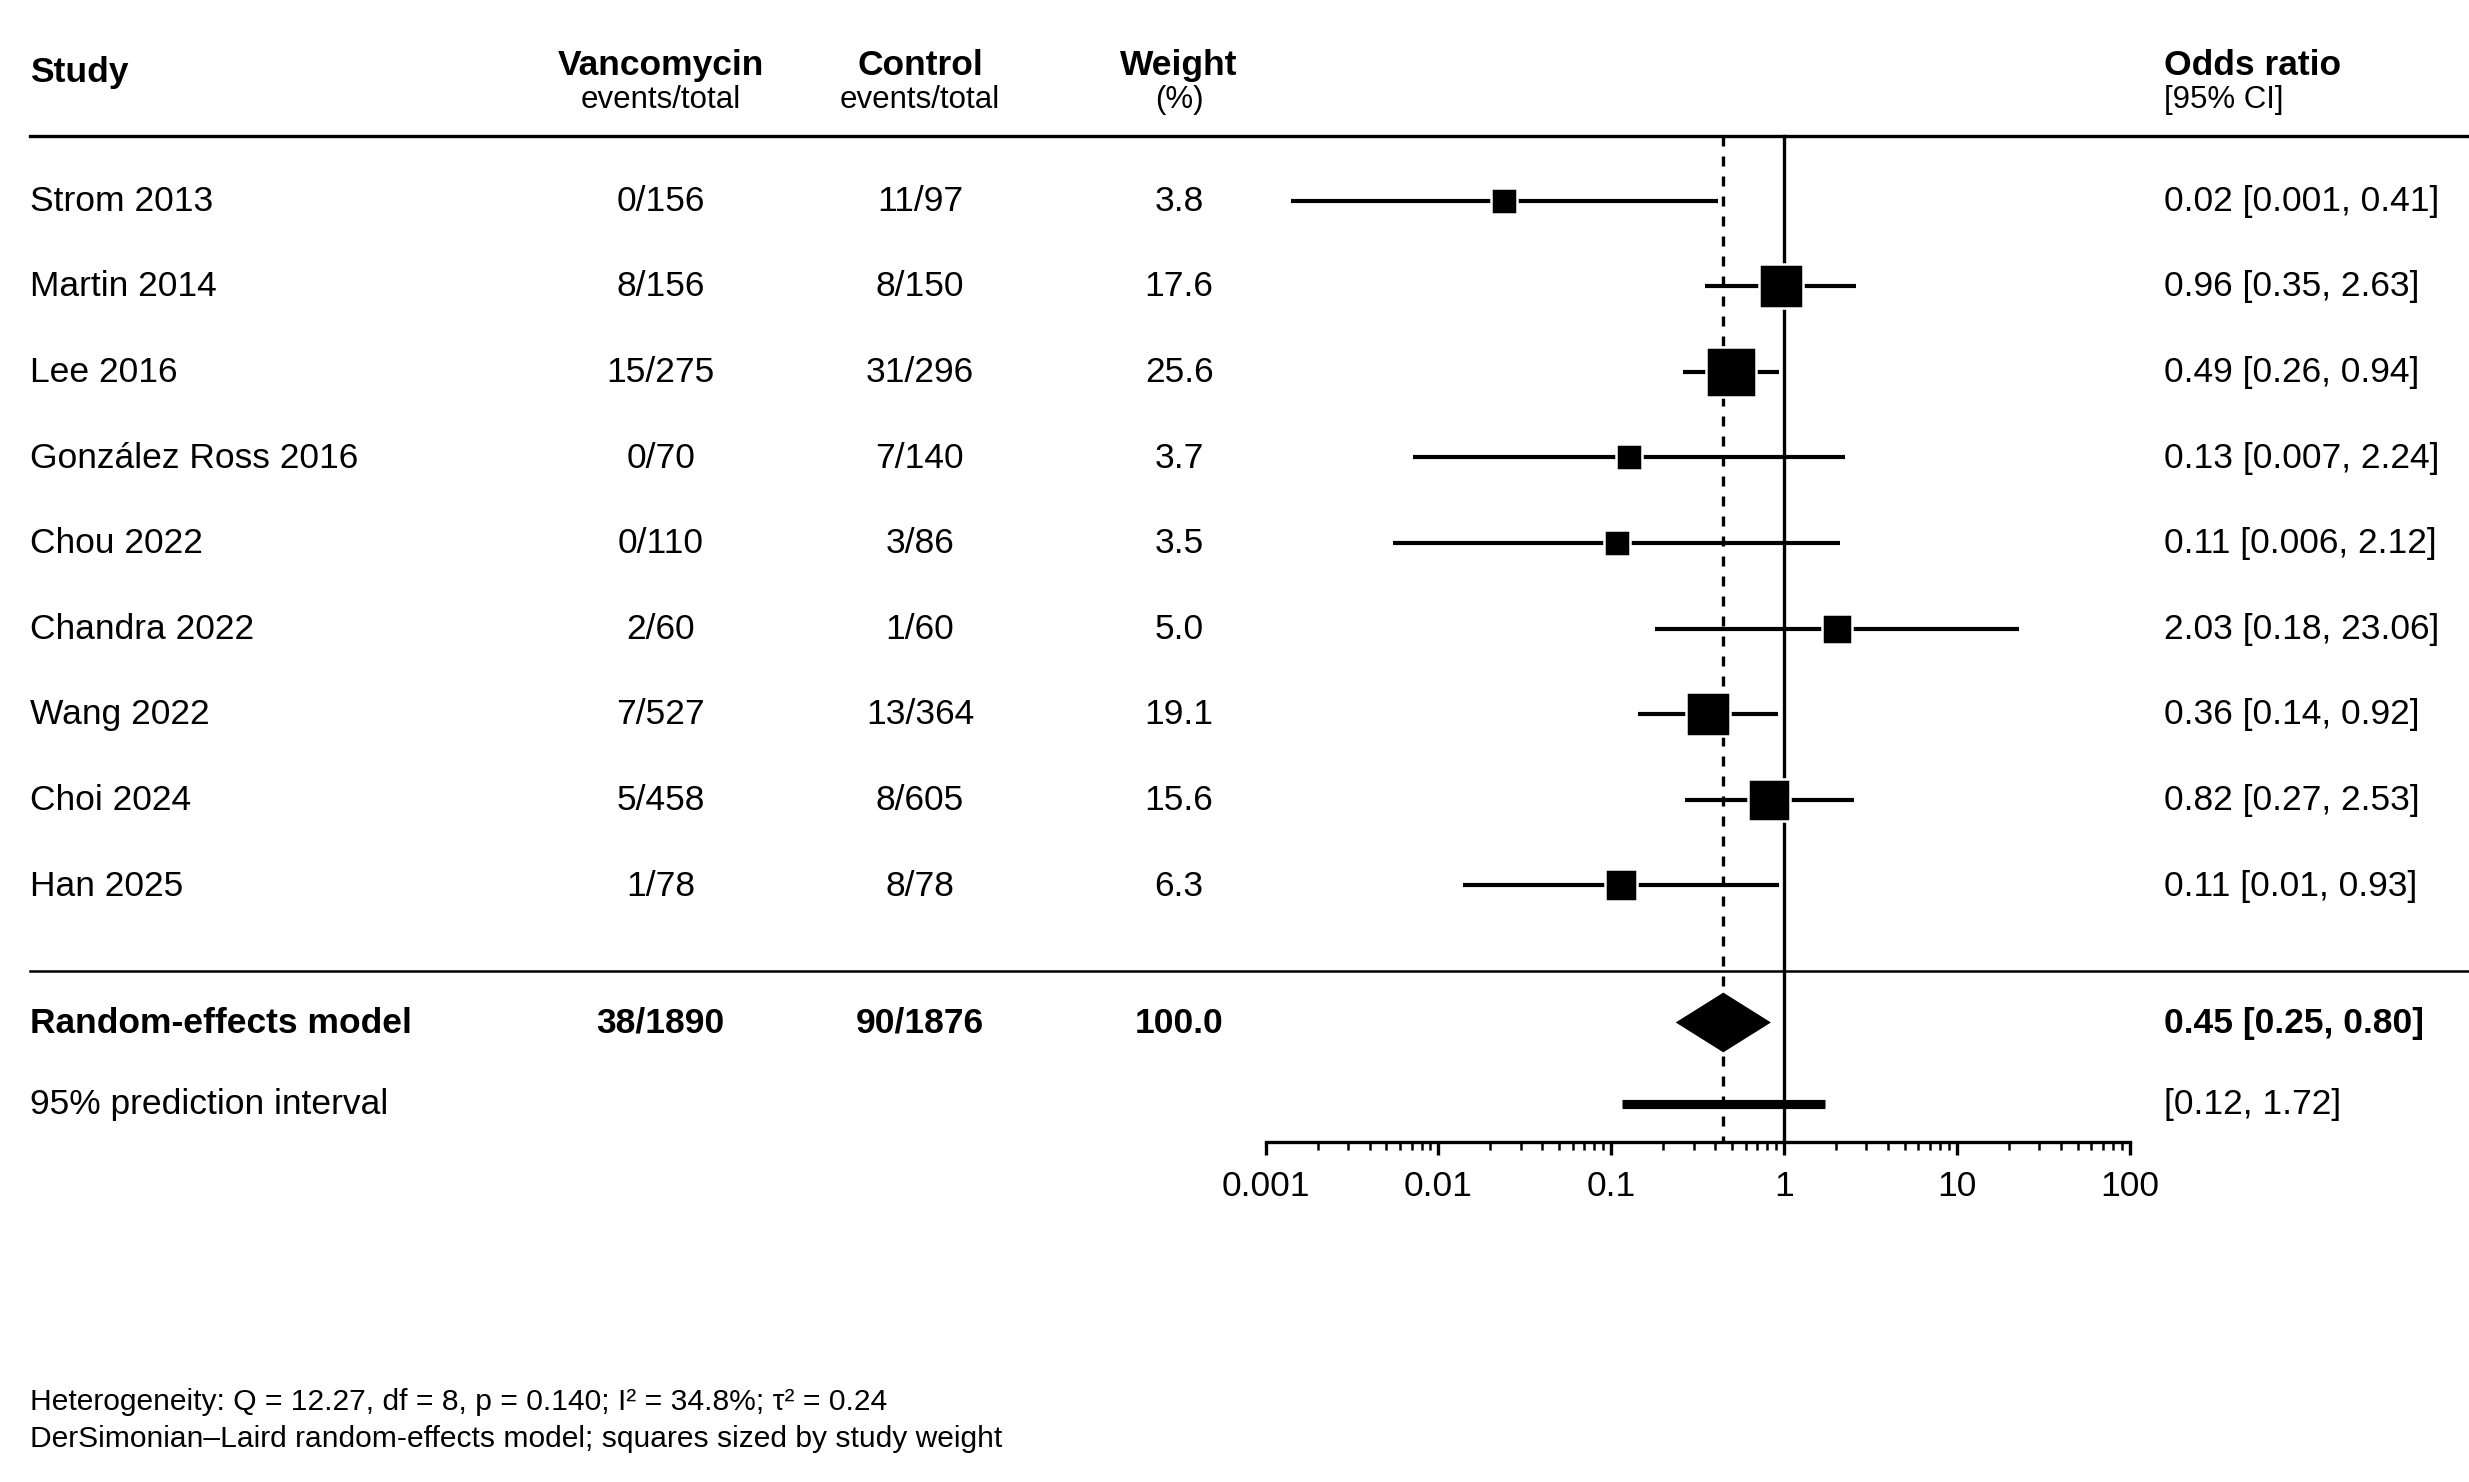

In [17]:
# Forest plot for intrawound vancomycin powder vs control, odds of SSI (9 studies).

import math
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.patches import Polygon
from scipy import stats

XLSX = "FINAL_vancomycin_meta_analysis_data.xlsx"
try:
    from google.colab import files  # allows use in Google Colab
    if not os.path.exists(XLSX):
        XLSX = next(iter(files.upload()))
except ImportError:
    matplotlib.use("Agg")

# Display accents in the name of authors who have one
LABELS = {"Gonzalez Ross 2016": "González Ross 2016"}


d = pd.read_excel(XLSX, sheet_name="Data").dropna(subset=["events1", "n1", "events2", "n2"])
d = d.reset_index(drop=True)
e1, n1, e2, n2 = (d[c].astype(int).values for c in ("events1", "n1", "events2", "n2"))

a, b, c, dd = e1, n1 - e1, e2, n2 - e2
zero = (a == 0) | (b == 0) | (c == 0) | (dd == 0)
a, b, c, dd = (x + 0.5 * zero for x in (a, b, c, dd))
y = np.log(a * dd / (b * c))
v = 1 / a + 1 / b + 1 / c + 1 / dd
Z = stats.norm.ppf(0.975)

k = len(y)
w = 1 / v
Q = np.sum(w * (y - np.sum(w * y) / w.sum()) ** 2)
df = k - 1
I2 = max(0.0, (Q - df) / Q) * 100
tau2 = max(0.0, (Q - df) / (w.sum() - (w ** 2).sum() / w.sum()))
wr = 1 / (v + tau2)
mu = np.sum(wr * y) / wr.sum()
se = math.sqrt(1 / wr.sum())
pi_half = stats.t.ppf(0.975, k - 2) * math.sqrt(tau2 + se ** 2)
p_q = stats.chi2.sf(Q, df)
weights = wr / wr.sum() * 100

OR, LO, HI = np.exp(y), np.exp(y - Z * np.sqrt(v)), np.exp(y + Z * np.sqrt(v))
P_OR, P_LO, P_HI = math.exp(mu), math.exp(mu - Z * se), math.exp(mu + Z * se)
PI_LO, PI_HI = math.exp(mu - pi_half), math.exp(mu + pi_half)

def fmt(x):
    # Format values to two decimal places or three if the value is below 0.01
    return f"{x:.3f}" if x < 0.01 else f"{x:.2f}"



font = "Liberation Sans" if any("Liberation Sans" in f.name for f in font_manager.fontManager.ttflist) else "DejaVu Sans"
plt.rcParams.update({"font.family": font, "font.size": 8.5})
INK, MUTED, RULE = "#000000", "#000000", "#000000"

XMIN, XMAX = 0.001, 100
rows = k + 4                                  # header, studies, gap, pooled, prediction interval
fig_w, fig_h = 9.6, 0.3 * rows + 1.4
fig = plt.figure(figsize=(fig_w, fig_h), dpi=300)

ax = fig.add_axes([0.43, 0.22, 0.30, 0.70])
ax.set_xscale("log")
ax.set_xlim(XMIN, XMAX)
ax.set_ylim(rows - 0.5, -0.5)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(INK)
ax.spines["bottom"].set_linewidth(0.8)
ax.set_yticks([])
ax.set_xticks([0.001, 0.01, 0.1, 1, 10, 100])
ax.set_xticklabels(["0.001", "0.01", "0.1", "1", "10", "100"])
ax.tick_params(axis="x", colors=INK, width=0.8, length=3)
ax.plot([1, 1], [0.75, rows - 0.5], color=INK, lw=0.8, zorder=1)
ax.plot([P_OR, P_OR], [0.75, rows - 0.5], color=RULE, lw=0.8, ls=(0, (3, 3)), zorder=1)

trans = ax.get_yaxis_transform()
COLS = {"study": -1.43, "vanco": -0.70, "control": -0.40, "weight": -0.10, "or": 1.04}


def text(col, row, s, **kw):
    kw.setdefault("color", INK)
    ax.text(COLS[col], row, s, transform=trans, va="center",
            ha="left" if col in ("study", "or") else "center", clip_on=False, **kw)


# Header
hdr = dict(fontweight="bold")
text("study", 0, "Study", **hdr)
text("vanco", -0.08, "Vancomycin", **hdr); text("vanco", 0.32, "events/total", color=MUTED, fontsize=7.5)
text("control", -0.08, "Control", **hdr);  text("control", 0.32, "events/total", color=MUTED, fontsize=7.5)
text("weight", -0.08, "Weight", **hdr);    text("weight", 0.32, "(%)", color=MUTED, fontsize=7.5)
text("or", -0.08, "Odds ratio", **hdr);    text("or", 0.32, "[95% CI]", color=MUTED, fontsize=7.5)
ax.plot([-1.43, 1.42], [0.75, 0.75], transform=trans, color=INK, lw=0.8, clip_on=False)

# Studies
max_w = weights.max()
for i in range(k):
    r = i + 1.5
    text("study", r, LABELS.get(d.study[i], d.study[i]))
    text("vanco", r, f"{e1[i]}/{n1[i]}")
    text("control", r, f"{e2[i]}/{n2[i]}")
    text("weight", r, f"{weights[i]:.1f}")
    text("or", r, f"{fmt(OR[i])} [{fmt(LO[i])}, {fmt(HI[i])}]")
    lo, hi = max(LO[i], XMIN), min(HI[i], XMAX)
    ax.plot([lo, hi], [r, r], color=INK, lw=1.0, solid_capstyle="butt", zorder=2)
    if HI[i] > XMAX:
        ax.annotate("", xy=(XMAX, r), xytext=(XMAX / 2.2, r),
                    arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.0, mutation_scale=7))
    if LO[i] < XMIN:
        ax.annotate("", xy=(XMIN, r), xytext=(XMIN * 2.2, r),
                    arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.0, mutation_scale=7))
    size = 9 * math.sqrt(weights[i] / max_w) + 3   # marker side in points and area tracks weight
    ax.plot(OR[i], r, marker="s", ms=size, color=INK, mec="white", mew=0.6, zorder=3)

# Pooled diamond shape and prediction interval
rp = k + 2.1
ax.plot([-1.43, 1.42], [rp - 0.6, rp - 0.6], transform=trans, color=RULE, lw=0.6, clip_on=False)
text("study", rp, "Random-effects model", fontweight="bold")
text("vanco", rp, f"{e1.sum()}/{n1.sum()}", fontweight="bold")
text("control", rp, f"{e2.sum()}/{n2.sum()}", fontweight="bold")
text("weight", rp, "100.0", fontweight="bold")
text("or", rp, f"{P_OR:.2f} [{P_LO:.2f}, {P_HI:.2f}]", fontweight="bold")
ax.add_patch(Polygon([(P_LO, rp), (P_OR, rp - 0.32), (P_HI, rp), (P_OR, rp + 0.32)],
                     closed=True, color=INK, zorder=3))

rpi = rp + 0.95
text("study", rpi, "95% prediction interval", color=MUTED)
text("or", rpi, f"[{PI_LO:.2f}, {PI_HI:.2f}]", color=MUTED)
ax.plot([PI_LO, PI_HI], [rpi, rpi], color=MUTED, lw=2.2, solid_capstyle="butt", zorder=2)

# Heterogeneity statistics
ax.text(-1.43, -0.22,
         f"Heterogeneity: Q = {Q:.2f}, df = {df}, p = {p_q:.3f}; I² = {I2:.1f}%; τ² = {tau2:.2f}\n"
         "DerSimonian–Laird random-effects model; squares sized by study weight",
         #"0.5 added to each cell of studies with a zero cell.", # Keep if needed
         transform=ax.transAxes, color=MUTED, fontsize=7.2, ha="left", va="top", linespacing=1.4, clip_on=False)

for ext in ("png", "pdf"):
    fig.savefig(f"forest_plot.{ext}", dpi=300, facecolor="white", bbox_inches="tight", pad_inches=0.15)
print(f"Pooled OR {P_OR:.2f} ({P_LO:.2f}-{P_HI:.2f}); I2 {I2:.1f}%; PI {PI_LO:.2f}-{PI_HI:.2f}")
print("Saved forest_plot.png and forest_plot.pdf")

In [18]:
# Determine the power of Cochran's Q test to detect heterogeneity with the 9 vancomycin studies with two methods for confirmation
# Method 1: Analytic approximation (Hedges & Pigott 2001): under true heterogeneity tau^2, Q is approximately a scaled chi-square with the mean and variance below, using each study's within-study variance
# Method 2: Monte Carlo simulation generate new 2x2 tables from binomial draws with a true pooled OR of 0.45 and between-study SD tau, re-run the Q test, and count how often it is significant
# Power is shown across a range of true tau^2 values (and the I^2 they correspond to), not only at the observed tau^2 = 0.24, because power computed at the observed result just restates the p-value


import numpy as np
from scipy import stats

# The 9 studies (vanco / control)
e1 = np.array([0, 8, 15, 0, 0, 2, 7, 5, 1]);       n1 = np.array([156, 156, 275, 70, 110, 60, 527, 458, 78])
e2 = np.array([11, 8, 31, 7, 3, 1, 13, 8, 8]);     n2 = np.array([97, 150, 296, 140, 86, 60, 364, 605, 78])
k = len(n1)
POOLED_OR = 0.45
TAU2_GRID = [0.05, 0.1, 0.24, 0.5, 1.0, 2.0]       # 0.24 = observed value
ALPHAS = [0.10, 0.05]
N_SIM = 5000
rng = np.random.default_rng(2026)


def log_or_var(a1, m1, a2, m2):
    # log OR and variance per study and 0.5 added to every cell of tables with a zero cell
    a, b, c, d = a1, m1 - a1, a2, m2 - a2
    zero = (a == 0) | (b == 0) | (c == 0) | (d == 0)
    a, b, c, d = (x + 0.5 * zero for x in (a, b, c, d))
    return np.log(a * d / (b * c)), 1 / a + 1 / b + 1 / c + 1 / d


def cochran_q(y, v):
    w = 1 / v
    return np.sum(w * (y - np.sum(w * y, axis=-1, keepdims=True) / np.sum(w, axis=-1, keepdims=True)) ** 2, axis=-1)


# Typical within-study variances from the observed data
_, v_obs = log_or_var(e1, n1, e2, n2)
w = 1 / v_obs
S1, S2, S3 = w.sum(), (w ** 2).sum(), (w ** 3).sum()
c_dl = S1 - S2 / S1


def analytic_power(tau2, alpha):
    # Hedges & Pigott (2001): Q ~ a * chi2(b) with matched mean and variance
    mean = (k - 1) + tau2 * c_dl
    var = 2 * (k - 1) + 4 * tau2 * c_dl + 2 * tau2 ** 2 * (S2 - 2 * S3 / S1 + S2 ** 2 / S1 ** 2)
    a, b = var / (2 * mean), 2 * mean ** 2 / var
    crit = stats.chi2.ppf(1 - alpha, k - 1)
    return stats.chi2.sf(crit / a, b)


def simulated_power(tau2, alpha):
    # Simulate binomial 2x2 tables around a pooled OR of 0.45 with between-study variance tau2
    p0 = e2 / n2  # observed control-group risks
    theta = np.log(POOLED_OR) + rng.normal(0, np.sqrt(tau2), (N_SIM, k))
    p1 = 1 / (1 + np.exp(-(np.log(p0 / (1 - p0)) + theta)))
    a1 = rng.binomial(n1, p1)
    a2 = rng.binomial(n2, np.broadcast_to(p0, (N_SIM, k)))
    y, v = log_or_var(a1, n1, a2, n2)
    q = cochran_q(y, v)
    return np.mean(stats.chi2.sf(q, k - 1) < alpha)


def i2_for(tau2):
    # I^2 implied by a true tau^2 given the typical within-study variance (Higgins & Thompson)
    s2 = (k - 1) * S1 / (S1 ** 2 - S2)
    return 100 * tau2 / (tau2 + s2)


print(f"Power of Cochran's Q test, k = {k} studies, true pooled OR = {POOLED_OR}\n")
print(f"{'true tau²':>9} {'≈ I²':>6} | " + " | ".join(f"{'analytic':>8} {'simulated':>9} (α={a:.2f})" for a in ALPHAS))
for t2 in TAU2_GRID:
    cells = [f"{analytic_power(t2, a):8.0%} {simulated_power(t2, a):9.0%}         " for a in ALPHAS]
    tag = "  <- observed" if t2 == 0.24 else ""
    print(f"{t2:9.2f} {i2_for(t2):5.0f}% | " + " | ".join(cells) + tag)
print("\nType I error check (no true heterogeneity, tau² = 0): "
      + ", ".join(f"α={a:.2f}: simulated {simulated_power(0.0, a):.1%}" for a in ALPHAS))

Power of Cochran's Q test, k = 9 studies, true pooled OR = 0.45

true tau²   ≈ I² | analytic simulated (α=0.10) | analytic simulated (α=0.05)
     0.05    10% |      15%        5%          |       8%        2%         
     0.10    18% |      21%       10%          |      13%        5%         
     0.24    35% |      37%       26%          |      26%       16%           <- observed
     0.50    53% |      58%       49%          |      49%       39%         
     1.00    69% |      78%       74%          |      71%       66%         
     2.00    82% |      90%       91%          |      87%       86%         

Type I error check (no true heterogeneity, tau² = 0): α=0.10: simulated 2.3%, α=0.05: simulated 0.8%


In [19]:
# Chou et al.: alternative vancomycin group size of 100 instead of 110
alt = data.copy()
alt.loc[alt.study.str.startswith("Chou"), "n1"] = 100
yc, vc, _ = log_or(alt.events1.values, alt.n1.values, alt.events2.values, alt.n2.values)
chou100 = meta(yc, vc)
print(f"Chou n = 100: OR {chou100['OR']:.2f} ({chou100['lo']:.2f}–{chou100['hi']:.2f}), I² {chou100['I2']:.1f}%")

# Restricted to studies not at serious risk of bias (ROBINS-I V2 moderate or RoB 2 some concerns)
not_serious = data.study.str.startswith(("Martin", "Wang", "Han", "Chandra")).values
rest = meta(y[not_serious], v[not_serious])
print(f"Not at serious risk of bias ({not_serious.sum()} studies, "
      f"{data.n1[not_serious].sum() + data.n2[not_serious].sum():,} patients): "
      f"OR {rest['OR']:.2f} ({rest['lo']:.2f}–{rest['hi']:.2f}), I² {rest['I2']:.1f}%")

# GRADE inputs
# Share of the random-effects weight from studies at serious risk of bias
print(f"Weight from studies at serious risk of bias: {res['re_weight'][~not_serious].sum():.1f}%")

# Absolute effect with its 95% CI (pooled OR and CI applied to the pooled control risk)
def risk_with(or_):
    return or_ * p0 / (1 - p0 + or_ * p0)
print(f"Risk with vancomycin {risk_with(res['OR']) * 1000:.0f} per 1,000 "
      f"({risk_with(res['lo']) * 1000:.0f} to {risk_with(res['hi']) * 1000:.0f}); "
      f"{(p0 - risk_with(res['OR'])) * 1000:.0f} fewer per 1,000 "
      f"({(p0 - risk_with(res['hi'])) * 1000:.0f} to {(p0 - risk_with(res['lo'])) * 1000:.0f} fewer)")

# Optimal information size: control risk p0, 25% relative risk reduction, two-sided alpha 0.05, power 80%
p_v = p0 * 0.75
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
ois = 2 * z ** 2 * (p0 * (1 - p0) + p_v * (1 - p_v)) / (p0 - p_v) ** 2
print(f"Optimal information size: {ois:,.0f} patients (pooled: {data.n1.sum() + data.n2.sum():,} patients, "
      f"{data.events1.sum() + data.events2.sum()} events)")

Chou n = 100: OR 0.45 (0.25–0.80), I² 34.1%
Not at serious risk of bias (4 studies, 1,473 patients): OR 0.53 (0.21–1.33), I² 42.4%
Weight from studies at serious risk of bias: 52.1%
Risk with vancomycin 22 per 1,000 (12 to 39); 26 fewer per 1,000 (9 to 36 fewer)
Optimal information size: 8,769 patients (pooled: 3,766 patients, 128 events)


In [20]:
# Confirm the version of Python, libraries, frameworks, etc.
import sys, numpy, scipy, statsmodels, pandas
print(f"Python {sys.version.split()[0]}, NumPy {numpy.__version__}, SciPy {scipy.__version__}, "
      f"pandas {pandas.__version__}, statsmodels {statsmodels.__version__}")

Python 3.13.18, NumPy 2.4.6, SciPy 1.16.3, pandas 2.2.3, statsmodels 0.15.0


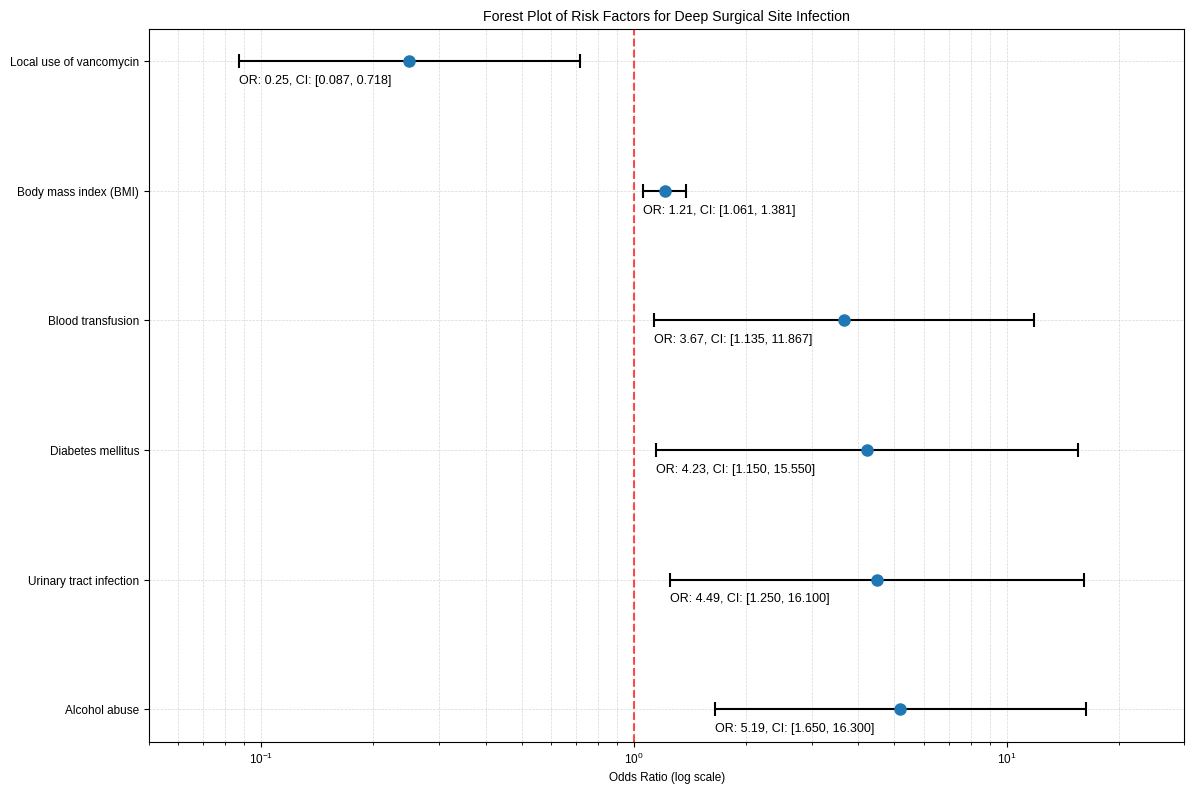

In [ ]:
# Figure 6
import matplotlib.pyplot as plt
import numpy as np

factors = ["Local use of vancomycin", "Body mass index (BMI)", "Blood transfusion",
           "Diabetes mellitus", "Urinary tract infection", "Alcohol abuse"]
odds_ratios = [0.25, 1.21, 3.67, 4.23, 4.49, 5.19]
ci_lower = [0.087, 1.061, 1.135, 1.150, 1.250, 1.650]
ci_upper = [0.718, 1.381, 11.867, 15.550, 16.100, 16.300]

y = np.arange(len(factors))
xerr = [np.subtract(odds_ratios, ci_lower), np.subtract(ci_upper, odds_ratios)]

fig, ax = plt.subplots(figsize=(12, 8))
ax.errorbar(odds_ratios, y, xerr=xerr, fmt="o", color="C0", ecolor="black",
            elinewidth=1.5, capsize=5, capthick=1.5, markersize=8)
ax.axvline(x=1, color="red", linestyle="--", alpha=0.7, linewidth=1.5)

for yi, or_, lo, hi in zip(y, odds_ratios, ci_lower, ci_upper):
    ax.text(lo, yi + 0.15, f"OR: {or_:.2f}, CI: [{lo:.3f}, {hi:.3f}]", va="center", ha="left", fontsize=9)

ax.set_xscale("log")
ax.set_xlim(0.05, 30)
ax.set_yticks(y)
ax.set_yticklabels(factors)
ax.invert_yaxis()
ax.set_xlabel("Odds Ratio (log scale)")
ax.set_title("Forest Plot of Risk Factors for Deep Surgical Site Infection")
ax.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.savefig("risk_factor_forest_plot.png", dpi=300)
plt.show()

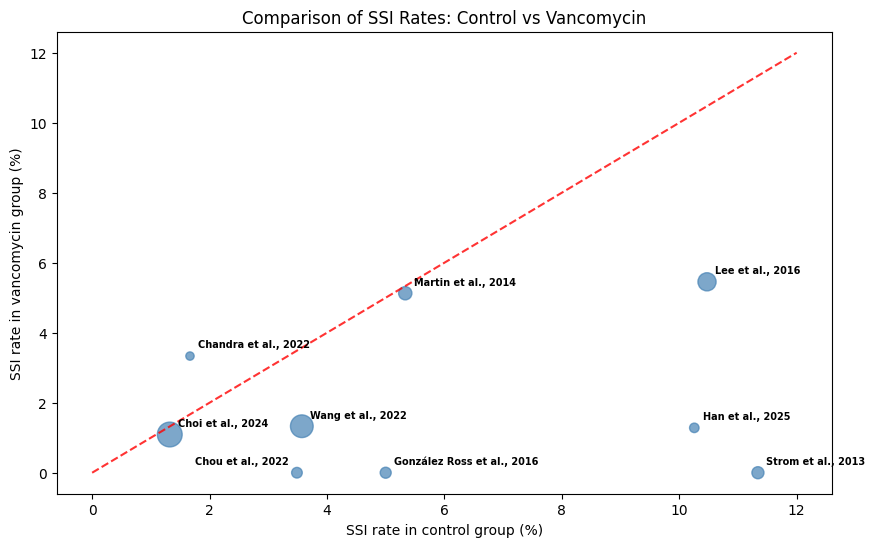

In [5]:
# Figure 8
import matplotlib.pyplot as plt

# Bubble area = total sample size / 10 to differentiate sample size impact in each study
studies = ["Strom et al., 2013", "Martin et al., 2014", "Lee et al., 2016", "González Ross et al., 2016",
           "Chou et al., 2022", "Chandra et al., 2022", "Wang et al., 2022", "Choi et al., 2024", "Han et al., 2025"]
control_rate = [100*11/97, 100*8/150, 100*31/296, 100*7/140, 100*3/86, 100*1/60, 100*13/364, 100*8/605, 100*8/78]
vanco_rate   = [0, 100*8/156, 100*15/275, 0, 0, 100*2/60, 100*7/527, 100*5/458, 100*1/78]
total_n      = [253, 306, 571, 210, 196, 120, 891, 1063, 156]

plt.figure(figsize=(10, 6))
plt.scatter(control_rate, vanco_rate, s=[3*n / 10 for n in total_n], color="steelblue", alpha=0.7)
plt.plot([0, 12], [0, 12], "r--", alpha=0.8)          # line of no difference, equality line (y = x)

LABEL_LEFT = {"Chou et al., 2022"}
for name, x, y in zip(studies, control_rate, vanco_rate):
    left = name in LABEL_LEFT
    plt.annotate(name, (x, y), xytext=(-6 if left else 6, 6), textcoords="offset points",
                 ha="right" if left else "left", fontsize=7, fontweight='bold')



plt.xlabel("SSI rate in control group (%)")
plt.ylabel("SSI rate in vancomycin group (%)")
plt.title("Comparison of SSI Rates: Control vs Vancomycin")
plt.show()

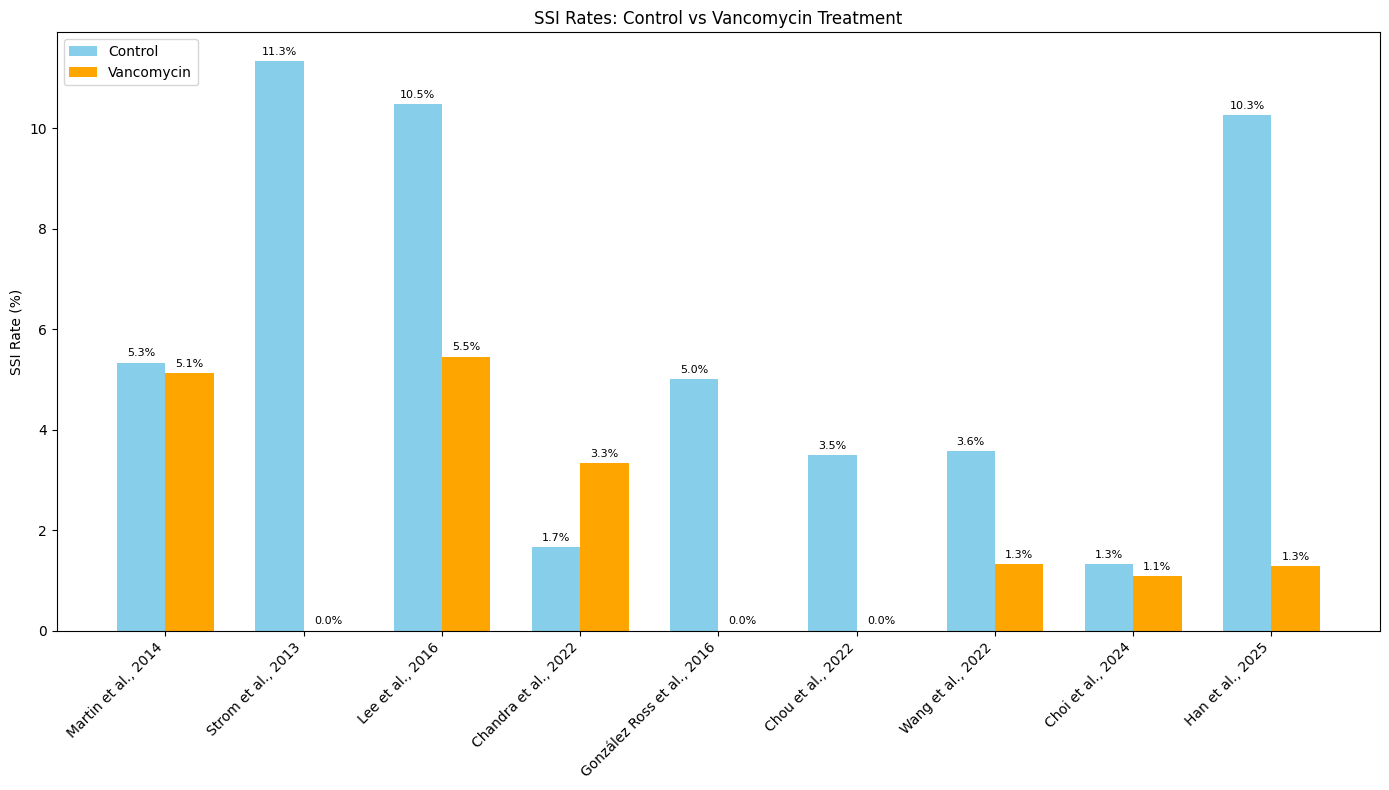

In [1]:
# Figure 9
import matplotlib.pyplot as plt
import numpy as np

studies = ["Martin et al., 2014", "Strom et al., 2013", "Lee et al., 2016", "Chandra et al., 2022",
           "González Ross et al., 2016", "Chou et al., 2022", "Wang et al., 2022", "Choi et al., 2024", "Han et al., 2025"]
control_rate = [100*8/150, 100*11/97, 100*31/296, 100*1/60, 100*7/140, 100*3/86, 100*13/364, 100*8/605, 100*8/78]
vanco_rate   = [100*8/156, 0.0,       100*15/275, 100*2/60, 0.0,       0.0,      100*7/527,  100*5/458, 100*1/78]

x = np.arange(len(studies))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 8))
bars_c = ax.bar(x - width / 2, control_rate, width, label="Control", color="skyblue")
bars_v = ax.bar(x + width / 2, vanco_rate, width, label="Vancomycin", color="orange")

ax.set_ylabel("SSI Rate (%)")
ax.set_title("SSI Rates: Control vs Vancomycin Treatment")
ax.set_xticks(x)
ax.set_xticklabels(studies, rotation=45, ha="right")
ax.legend(loc="upper left")

for bars in (bars_c, bars_v):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3),
                    textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig("Figure_9.tiff", dpi=300)
plt.show()

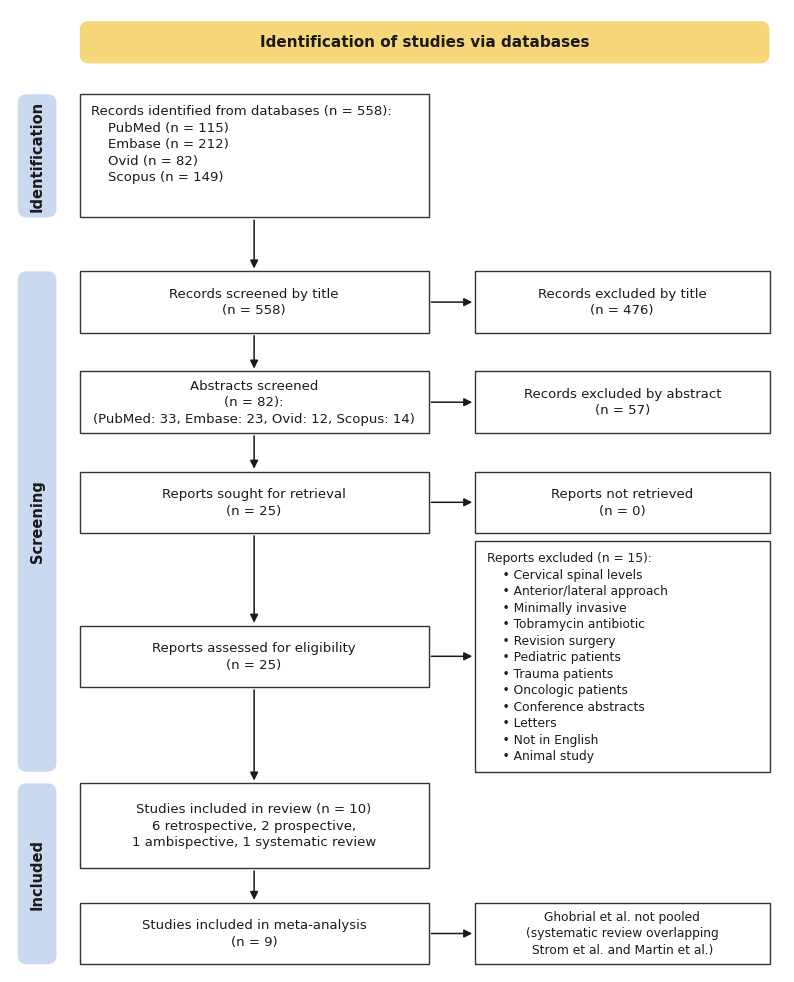

identified 558, screened 558, excluded by title 476, by abstract 57, full texts assessed 25, excluded 15, included 10, meta-analysis 9


In [ ]:
# PRISMA 2020 flow diagram (Figure 5)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Inputs
DATABASES = {"PubMed": 115, "Embase": 212, "Ovid": 82, "Scopus": 149}
DUPLICATES_REMOVED = None                # None prints a blank "[ ]" to fill in
ABSTRACTS_SCREENED = 33 + 23 + 12 + 14   # records passing title screening (per database, old diagram)
REPORTS_SOUGHT = 25                      # full texts obtainable
REPORTS_NOT_RETRIEVED = 0                # full texts unobtainable
STUDIES_INCLUDED = 10
STUDIES_IN_META = 9
DESIGNS = "6 retrospective, 2 prospective,\n1 ambispective, 1 systematic review"
# Reasons for exclusion (from the original diagram), listed without counts since unobtainable
EXCLUSION_REASONS = [
    "Cervical spinal levels", "Anterior/lateral approach", "Minimally invasive", "Tobramycin antibiotic",
    "Revision surgery", "Pediatric patients", "Trauma patients", "Oncologic patients",
    "Conference abstracts", "Letters", "Not in English", "Animal study",
]
META_NOTE = "Ghobrial et al. not pooled\n(systematic review overlapping\nStrom et al. and Martin et al.)"

# Derived counts
identified = sum(DATABASES.values())
screened = identified - (DUPLICATES_REMOVED or 0)
excluded_title = screened - ABSTRACTS_SCREENED
excluded_abstract = ABSTRACTS_SCREENED - REPORTS_SOUGHT
assessed = REPORTS_SOUGHT - REPORTS_NOT_RETRIEVED
excluded_fulltext = assessed - STUDIES_INCLUDED


def n(v):
    return f"(n = {v:,})" if v is not None else "(n = [   ])"


# Drawings for visualization
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9.5})
fig, ax = plt.subplots(figsize=(10, 12.5))
ax.set_xlim(0, 100)
ax.set_ylim(0, 125)
ax.axis("off")
INK, EDGE, PHASE_FILL, HEADER_FILL = "#1a1a1a", "#333333", "#C9DAF0", "#F6D77A"


def box(x, y, w, h, text, align="center", fill="white", bold_first=False, fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="square,pad=0", fc=fill, ec=EDGE, lw=1.0))
    lines = text.split("\n")
    if align == "center":
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", color=INK, fontsize=fs, linespacing=1.35)
    else:
        ax.text(x + 1.5, y + h - 1.4, text, ha="left", va="top", color=INK, fontsize=fs, linespacing=1.35)
    return (x, y, w, h)


def arrow_down(b1, b2):
    x = b1[0] + b1[2] / 2
    ax.annotate("", xy=(x, b2[1] + b2[3]), xytext=(x, b1[1]),
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.1, mutation_scale=12))


def arrow_right(b1, b2):
    y = b1[1] + b1[3] / 2
    ax.annotate("", xy=(b2[0], y), xytext=(b1[0] + b1[2], y),
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.1, mutation_scale=12))


def phase(y_top, y_bottom, label):
    ax.add_patch(FancyBboxPatch((1, y_bottom), 5, y_top - y_bottom, boxstyle="round,pad=0,rounding_size=1.2",
                                fc=PHASE_FILL, ec="none"))
    ax.text(3.5, (y_top + y_bottom) / 2, label, rotation=90, ha="center", va="center",
            fontsize=10.5, fontweight="bold", color=INK)


# Layout
LX, LW, RX, RW = 9, 45, 60, 38          # left (main) and right (exclusion) columns

ax.add_patch(FancyBboxPatch((LX, 118), RX + RW - LX, 5.5, boxstyle="round,pad=0,rounding_size=1.2",
                            fc=HEADER_FILL, ec="none"))
ax.text((LX + RX + RW) / 2, 120.75, "Identification of studies via databases", ha="center", va="center",
        fontsize=11, fontweight="bold", color=INK)

db_lines = "\n".join(f"    {k} {n(v)}" for k, v in DATABASES.items())
b_id = box(LX, 98, LW, 16, f"Records identified from databases {n(identified)}:\n{db_lines}", align="left")
#b_dup = box(RX, 100, RW, 12, f"Records removed before screening:\n    Duplicate records removed\n    {n(DUPLICATES_REMOVED)}",
#            align="left")
#arrow_right(b_id, b_dup)

b_title = box(LX, 83, LW, 8, f"Records screened by title\n{n(screened)}")
b_xtitle = box(RX, 83, RW, 8, f"Records excluded by title\n{n(excluded_title)}")
b_abs = box(LX, 70, LW, 8, f"Abstracts screened\n{n(ABSTRACTS_SCREENED)}:\n(PubMed: 33, Embase: 23, Ovid: 12, Scopus: 14)")
b_xabs = box(RX, 70, RW, 8, f"Records excluded by abstract\n{n(excluded_abstract)}")
b_sought = box(LX, 57, LW, 8, f"Reports sought for retrieval\n{n(REPORTS_SOUGHT)}")
b_notret = box(RX, 57, RW, 8, f"Reports not retrieved\n{n(REPORTS_NOT_RETRIEVED)}")
b_assess = box(LX, 37, LW, 8, f"Reports assessed for eligibility\n{n(assessed)}")
reasons = "\n".join(f"    \u2022 {r}" for r in EXCLUSION_REASONS)
b_xfull = box(RX, 26, RW, 30, f"Reports excluded {n(excluded_fulltext)}:\n{reasons}", align="left", fs=8.8)

for a, b in [(b_id, b_title), (b_title, b_abs), (b_abs, b_sought), (b_sought, b_assess)]:
    arrow_down(a, b)
for a, b in [(b_title, b_xtitle), (b_abs, b_xabs), (b_sought, b_notret), (b_assess, b_xfull)]:
    arrow_right(a, b)

b_incl = box(LX, 13.5, LW, 11, f"Studies included in review {n(STUDIES_INCLUDED)}\n{DESIGNS}")
b_meta = box(LX, 1, LW, 8, f"Studies included in meta-analysis\n{n(STUDIES_IN_META)}")
b_note = box(RX, 1, RW, 8, META_NOTE, fs=8.8)
arrow_down(b_assess, b_incl)
arrow_down(b_incl, b_meta)
arrow_right(b_meta, b_note)

phase(114, 98, "Identification")
phase(91, 26, "Screening")
phase(24.5, 1, "Included")

for ext in ("png", "pdf", "tiff"):
    fig.savefig(f"prisma_2020_flow.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"identified {identified}, screened {screened}, excluded by title {excluded_title}, by abstract {excluded_abstract}, "
      f"full texts assessed {assessed}, excluded {excluded_fulltext}, included {STUDIES_INCLUDED}, meta-analysis {STUDIES_IN_META}")

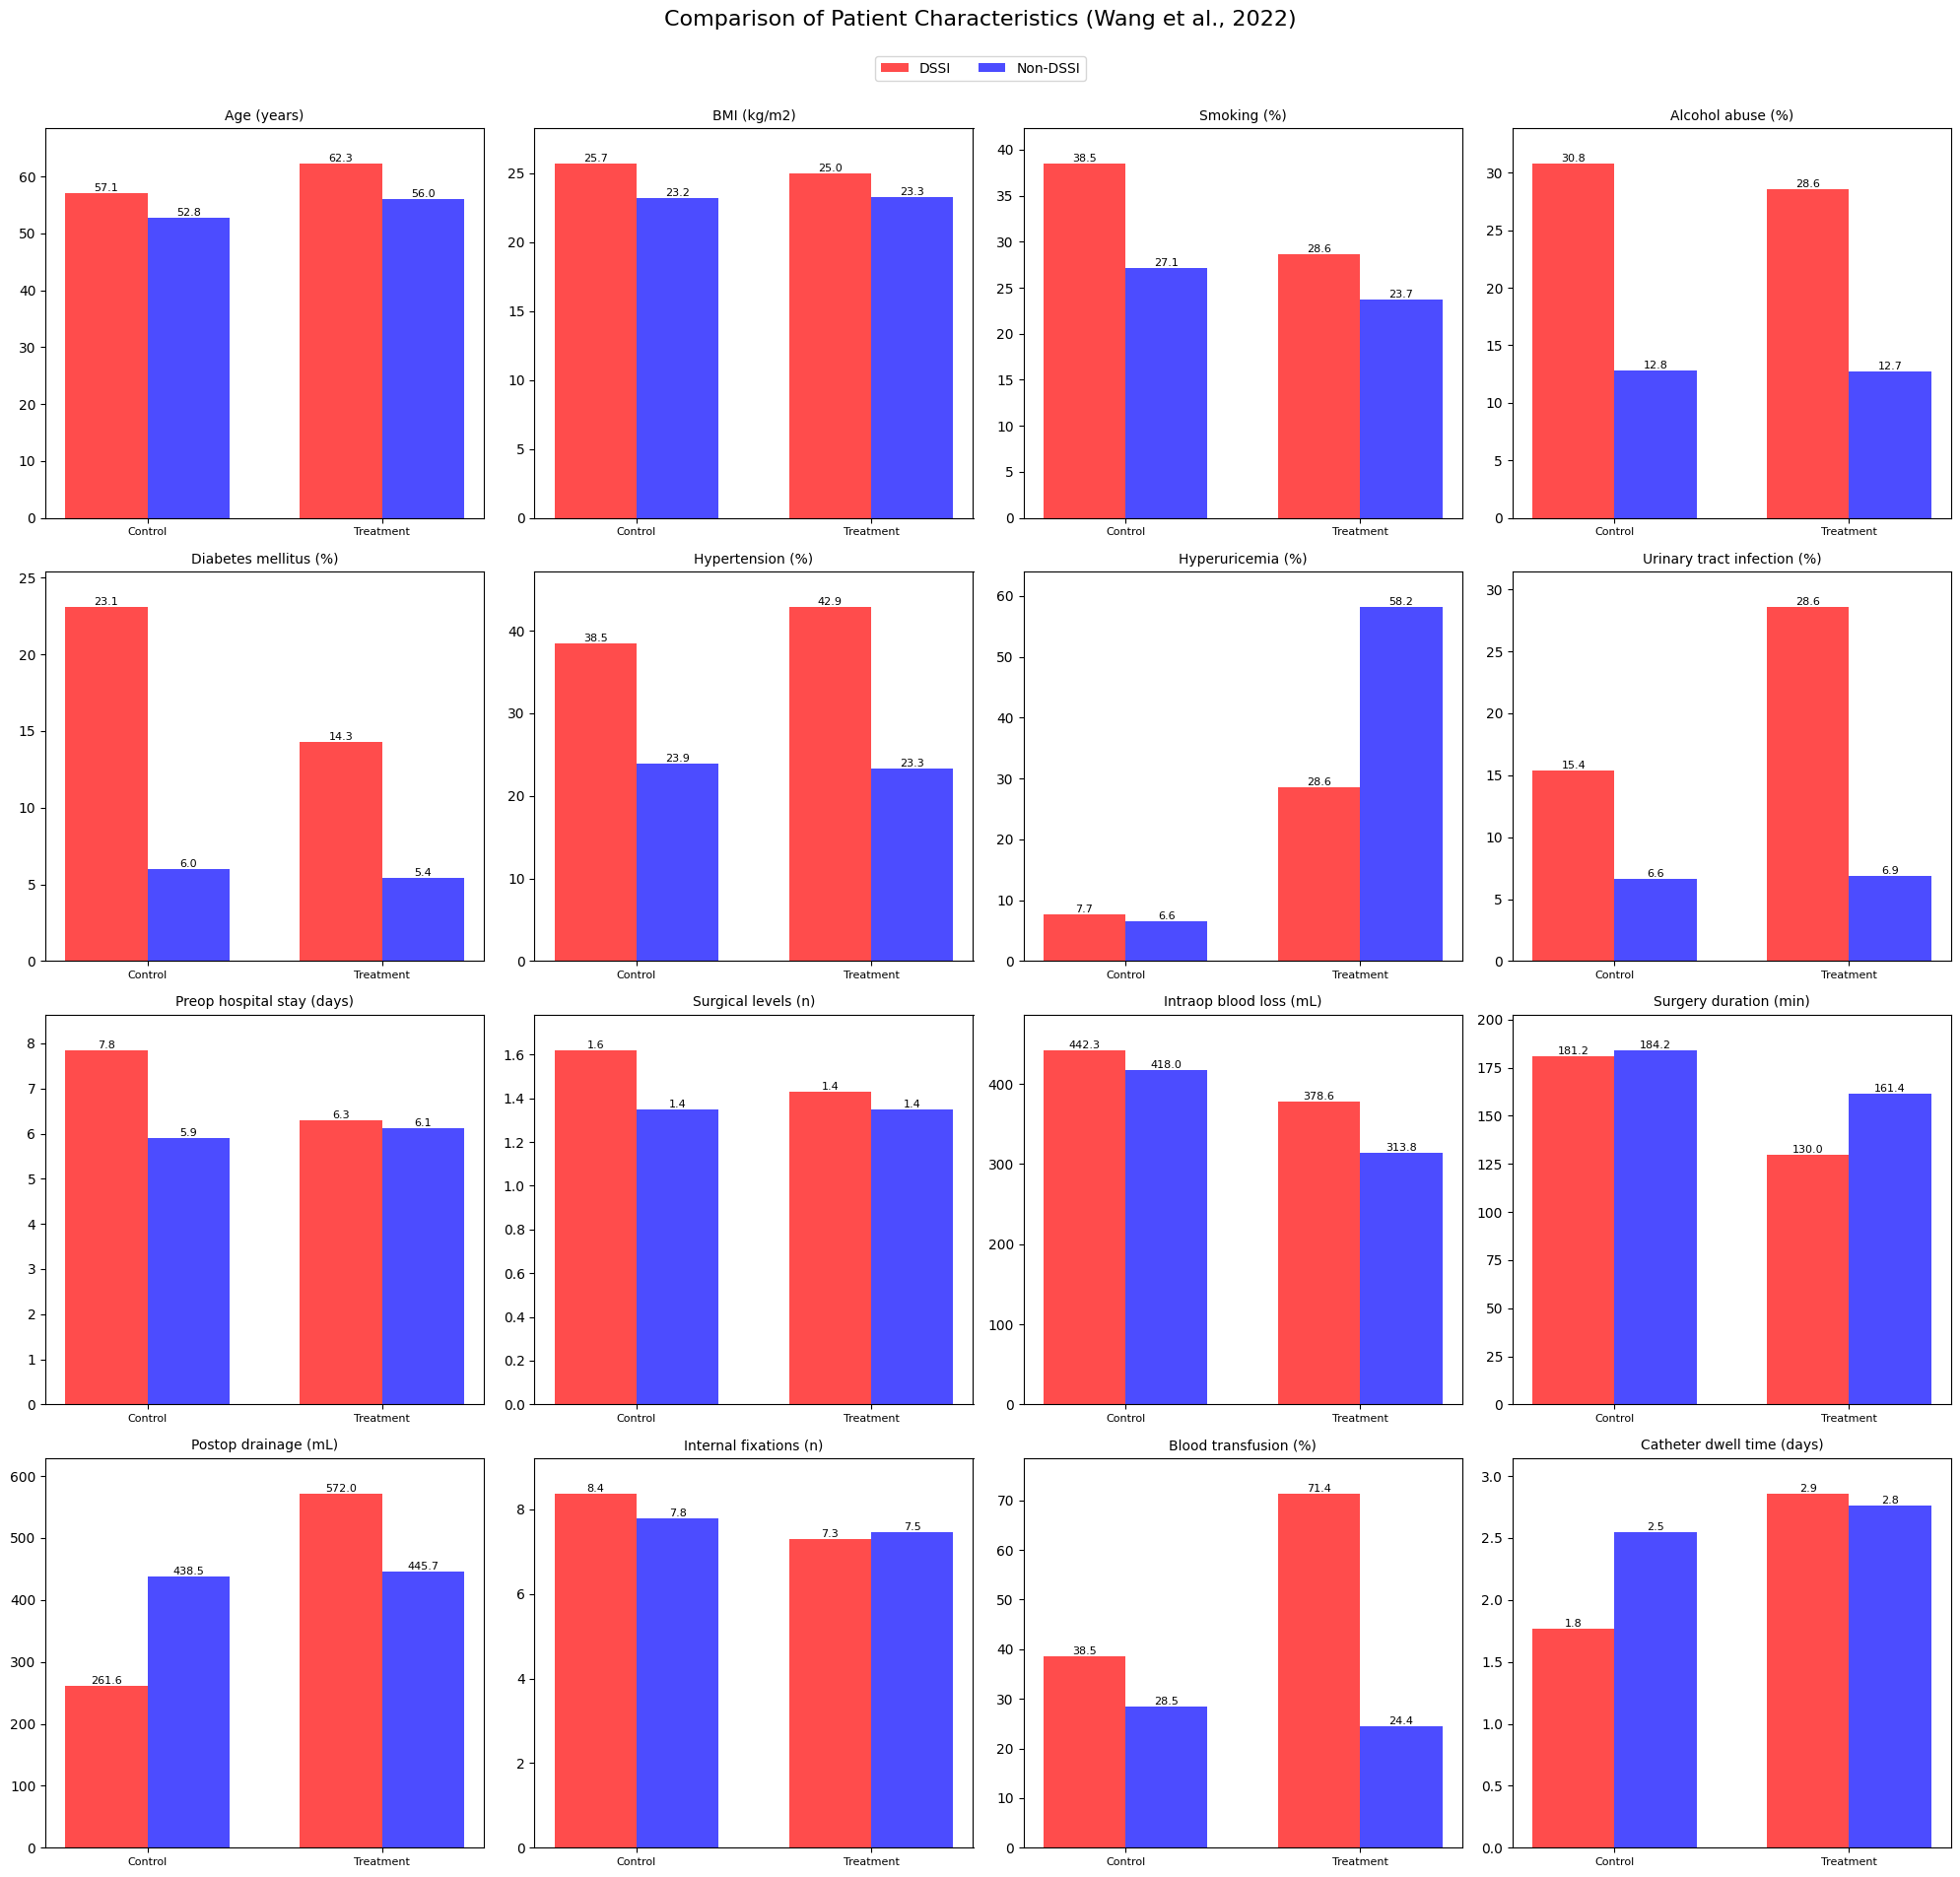

In [7]:
# Figure 10
import matplotlib.pyplot as plt
import numpy as np

# Data from Wang et al.'s Table 1
variables = [
    'Age (years)', 'BMI (kg/m2)', 'Smoking (%)', 'Alcohol abuse (%)',
    'Diabetes mellitus (%)', 'Hypertension (%)', 'Hyperuricemia (%)',
    'Urinary tract infection (%)', 'Preop hospital stay (days)',
    'Surgical levels (n)', 'Intraop blood loss (mL)',
    'Surgery duration (min)', 'Postop drainage (mL)',
    'Internal fixations (n)', 'Blood transfusion (%)',
    'Catheter dwell time (days)'
]

control_dssi = [57.08, 25.69, 38.5, 30.8, 23.1, 38.5, 7.7, 15.4, 7.85, 1.62, 442.31, 181.15, 261.62, 8.38, 38.5, 1.77]
control_non_dssi = [52.82, 23.20, 27.1, 12.8, 6.0, 23.9, 6.6, 6.6, 5.91, 1.35, 417.98, 184.15, 438.50, 7.80, 28.5, 2.55]
treatment_dssi = [62.29, 24.97, 28.6, 28.6, 14.3, 42.9, 28.6, 28.6, 6.29, 1.43, 378.57, 130.00, 572.00, 7.29, 71.4, 2.86]
treatment_non_dssi = [56.02, 23.28, 23.7, 12.7, 5.4, 23.3, 58.2, 6.9, 6.12, 1.35, 313.82, 161.38, 445.69, 7.47, 24.4, 2.76]

fig, axs = plt.subplots(4, 4, figsize=(20, 20))
fig.suptitle('Comparison of Patient Characteristics (Wang et al., 2022)', fontsize=16)

for i, (var, c_d, c_nd, t_d, t_nd) in enumerate(zip(variables, control_dssi, control_non_dssi, treatment_dssi, treatment_non_dssi)):
    ax = axs[i // 4, i % 4]

    x = np.arange(2)
    width = 0.35

    ax.bar(x - width/2, [c_d, t_d], width, label='DSSI', color='red', alpha=0.7)
    ax.bar(x + width/2, [c_nd, t_nd], width, label='Non-DSSI', color='blue', alpha=0.7)

    ax.set_title(var, fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels(['Control', 'Treatment'], fontsize=8)

    # Add value labels on top of each bar
    for j, v in enumerate([c_d, c_nd, t_d, t_nd]):
        ax.text(x[j//2] + (width/2 if j % 2 else -width/2), v, f'{v:.1f}',
                ha='center', va='bottom', fontsize=8)

    # Adjust y-axis to reduce gap in display
    ax.set_ylim(0, max([c_d, c_nd, t_d, t_nd]) * 1.1)

# Add a single legend for all subplots
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.96), ncol=2)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.subplots_adjust(top=0.92)  # Adjust top margin for main title and legend
plt.show()